# 02 · Perfil estadístico de quien abandona

Compara a los clientes que abandonan (churn = 1) con los que se quedan, sobre el dataset limpio
(`data/clean/telco_churn_clean.csv`, generado por `pipeline/clean.py`).

- Proporción de abandono con IC 95 % (Wilson).
- Variables 0/1: chi-cuadrado + V de Cramér (tamaño del efecto) + riesgo relativo = P(abandono | x=1) / P(abandono | x=0).
- Numéricas: Mann-Whitney U (no asume normalidad) + correlación biserial de rangos.
- p-valores corregidos por Bonferroni (muchas pruebas a la vez).

Salidas: `ml/reports/tables/churn_perfil.csv`, `ml/reports/figures/perfil/*.png`

In [1]:
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from telco import paths, style
from telco.data import NUMERIC, load_clean, wilson
from telco.style import CHURN, INK, LABELS, MUTED, STAY

style.apply()
pd.set_option("display.width", 200)
GROUP = {0: "Se queda", 1: "Abandona"}
df = load_clean().drop(columns="customer_id")

## 1. Proporción de abandono

Abandona: 1,869 de 7,043 (26.54%)  IC 95 % [25.5%, 27.6%]


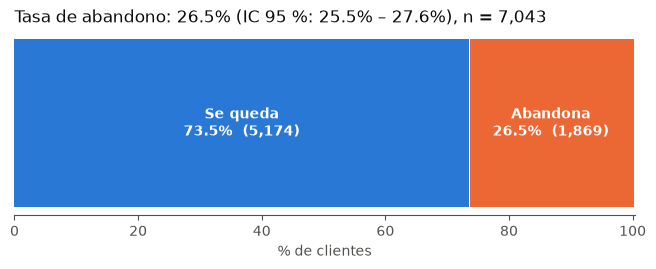

In [2]:
n1, n = int(df.churn.sum()), len(df)
ci = wilson(n1, n)
print(f"Abandona: {n1:,} de {n:,} ({n1 / n:.2%})  IC 95 % [{ci[0]:.1%}, {ci[1]:.1%}]")

n0 = n - n1
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh([0], [n0 / n * 100], color=STAY, height=0.5)
ax.barh([0], [n1 / n * 100], left=[n0 / n * 100 + 0.3], color=CHURN, height=0.5)
ax.text(n0 / n * 50, 0, f"Se queda\n{n0 / n:.1%}  ({n0:,})", ha="center", va="center", color="white", fontweight="bold")
ax.text(n0 / n * 100 + n1 / n * 50, 0, f"Abandona\n{n1 / n:.1%}  ({n1:,})", ha="center", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 100.3)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("% de clientes")
ax.set_title(f"Tasa de abandono: {n1 / n:.1%} (IC 95 %: {ci[0]:.1%} – {ci[1]:.1%}), n = {n:,}", loc="left")
style.save(fig, paths.figure("perfil", "perfil_proporcion.png"))

## 2. Pruebas por variable

In [3]:
def binary_stats(col: str) -> dict:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df[col], df["churn"]))
    rate1, rate0 = df.loc[df[col] == 1, "churn"].mean(), df.loc[df[col] == 0, "churn"].mean()
    return {
        "variable": col, "tipo": "binaria",
        "se_queda": df.loc[df.churn == 0, col].mean() * 100,   # % del grupo que tiene la característica
        "abandona": df.loc[df.churn == 1, col].mean() * 100,
        "churn_si_1": rate1 * 100, "churn_si_0": rate0 * 100,
        "riesgo_relativo": rate1 / rate0,
        "efecto": np.sqrt(chi2 / len(df)),  # V de Cramér (2x2 = phi)
        "p_valor": p,
    }


def numeric_stats(col: str) -> dict:
    a, b = df.loc[df.churn == 1, col], df.loc[df.churn == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    return {
        "variable": col, "tipo": "numérica",
        "se_queda": b.median(), "abandona": a.median(),  # medianas
        "efecto": abs(2 * u / (len(a) * len(b)) - 1),    # |biserial de rangos|
        "p_valor": p,
    }


res = pd.DataFrame([numeric_stats(c) if c in NUMERIC else binary_stats(c) for c in df.columns if c != "churn"])
res["p_bonferroni"] = (res["p_valor"] * len(res)).clip(upper=1)
res["significativo"] = res["p_bonferroni"] < 0.05
res["diff_pp"] = res["abandona"] - res["se_queda"]
res = res.sort_values("efecto", ascending=False)
res.round(4).to_csv(paths.table("churn_perfil.csv"), index=False)
b = res[res.tipo == "binaria"]
b[["variable", "se_queda", "abandona", "diff_pp", "churn_si_1", "churn_si_0", "riesgo_relativo", "efecto", "p_bonferroni"]].round(2)

,variable,se_queda,abandona,diff_pp,churn_si_1,churn_si_0,riesgo_relativo,efecto,p_bonferroni
19,contract_month_to_month,42.91,88.55,45.64,42.71,6.76,6.32,0.40,0.00
17,internet_service_fiber_optic,34.77,69.40,34.63,41.89,14.49,2.89,0.31,0.00
21,contract_two_year,31.83,2.57,-29.26,2.83,34.05,0.08,0.30,0.00
24,payment_method_electronic_check,25.01,57.30,32.29,45.29,17.06,2.65,0.30,0.00
18,internet_service_no,27.31,6.05,-21.26,7.40,31.83,0.23,0.23,0.00
13,paperless_billing,53.56,74.91,21.35,33.57,16.33,2.06,0.19,0.00
20,contract_one_year,25.26,8.88,-16.38,11.27,30.57,0.37,0.18,0.00
7,online_security,33.32,15.78,-17.54,14.61,31.33,0.47,0.17,0.00
10,tech_support,33.51,16.59,-16.93,15.17,31.19,0.49,0.16,0.00
3,dependents,34.48,17.44,-17.04,15.45,31.28,0.49,0.16,0.00


In [4]:
print("Numéricas (medianas):")
print(res[res.tipo == "numérica"][["variable", "se_queda", "abandona", "efecto", "p_bonferroni"]].round(2).to_string(index=False))
print("\nNo significativas:", ", ".join(res.loc[~res.significativo, "variable"]) or "ninguna")

Numéricas (medianas):
       variable  se_queda  abandona  efecto  p_bonferroni
         tenure     38.00     10.00    0.48           0.0
  total_charges   1679.52    703.55    0.30           0.0
monthly_charges     64.43     79.65    0.24           0.0

No significativas: phone_service, gender_male


## 3. Perfil típico (efecto ≥ 0,1 y significativo)

In [5]:
strong = b[(b.efecto >= 0.1) & b.significativo]
print("QUIEN ABANDONA tiene con más frecuencia:")
for r in strong[strong.diff_pp > 0].itertuples():
    print(f"  {LABELS[r.variable]:<32} {r.abandona:5.1f} % vs {r.se_queda:5.1f} %  -> abandono ×{r.riesgo_relativo:.2f}")
print("\nQUIEN SE QUEDA tiene con más frecuencia:")
for r in strong[strong.diff_pp < 0].itertuples():
    print(f"  {LABELS[r.variable]:<32} {r.se_queda:5.1f} % vs {r.abandona:5.1f} %  -> abandono ×{r.riesgo_relativo:.2f}")

QUIEN ABANDONA tiene con más frecuencia:
  Contrato mes a mes                88.6 % vs  42.9 %  -> abandono ×6.32
  Internet fibra óptica             69.4 % vs  34.8 %  -> abandono ×2.89
  Pago cheque electrónico           57.3 % vs  25.0 %  -> abandono ×2.65
  Factura electrónica               74.9 % vs  53.6 %  -> abandono ×2.06
  Cliente sénior                    25.5 % vs  12.9 %  -> abandono ×1.77

QUIEN SE QUEDA tiene con más frecuencia:
  Contrato 2 años                   31.8 % vs   2.6 %  -> abandono ×0.08
  Sin internet                      27.3 % vs   6.0 %  -> abandono ×0.23
  Contrato 1 año                    25.3 % vs   8.9 %  -> abandono ×0.37
  Seguridad en línea                33.3 % vs  15.8 %  -> abandono ×0.47
  Soporte técnico                   33.5 % vs  16.6 %  -> abandono ×0.49
  Tiene dependientes                34.5 % vs  17.4 %  -> abandono ×0.49
  Tiene pareja                      52.8 % vs  35.8 %  -> abandono ×0.60
  Pago tarjeta automática           24.9 

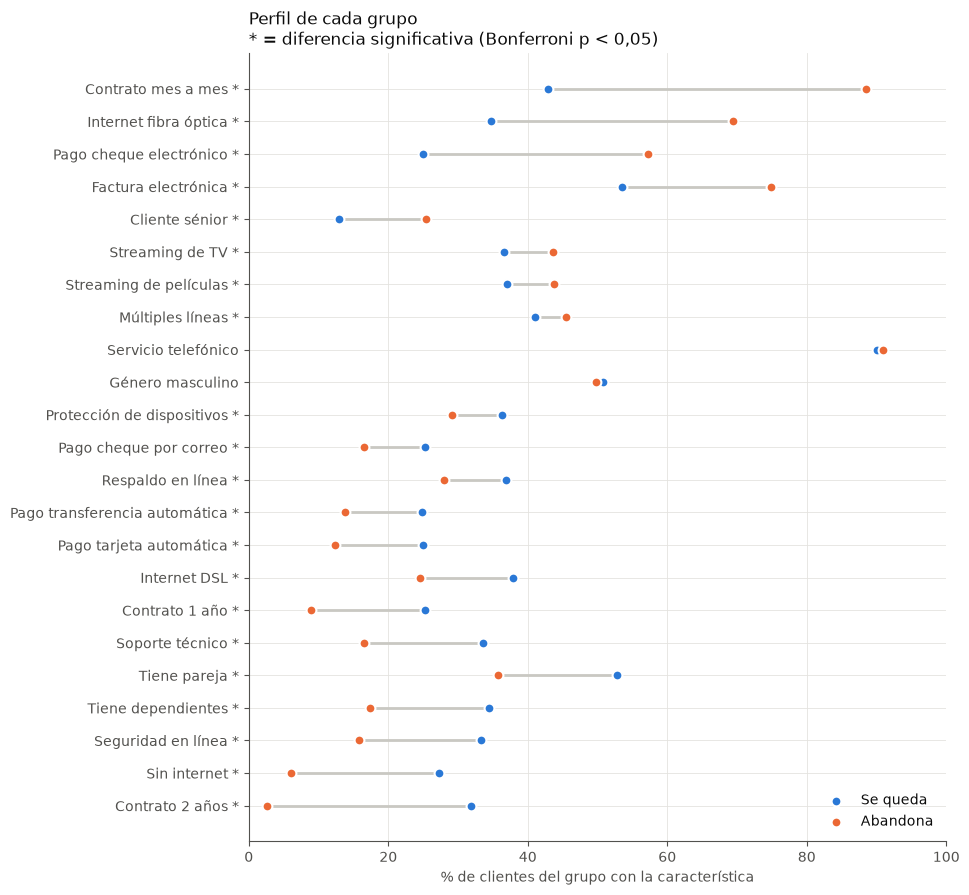

In [6]:
bb = b.sort_values("diff_pp")
y = np.arange(len(bb))
fig, ax = plt.subplots(figsize=(9, 0.38 * len(bb) + 1.5))
ax.hlines(y, bb["se_queda"], bb["abandona"], color="#c9c8c2", lw=2)
ax.scatter(bb["se_queda"], y, color=STAY, s=50, zorder=3, label="Se queda", edgecolor="white", linewidth=1.5)
ax.scatter(bb["abandona"], y, color=CHURN, s=50, zorder=3, label="Abandona", edgecolor="white", linewidth=1.5)
ax.set_yticks(y, [f"{LABELS[v]}{' *' if s else ''}" for v, s in zip(bb["variable"], bb["significativo"])])
ax.set_xlabel("% de clientes del grupo con la característica")
ax.set_xlim(0, 100)
ax.set_title("Perfil de cada grupo\n* = diferencia significativa (Bonferroni p < 0,05)", loc="left")
ax.legend(loc="lower right", frameon=False)
style.save(fig, paths.figure("perfil", "perfil_caracteristicas.png"))

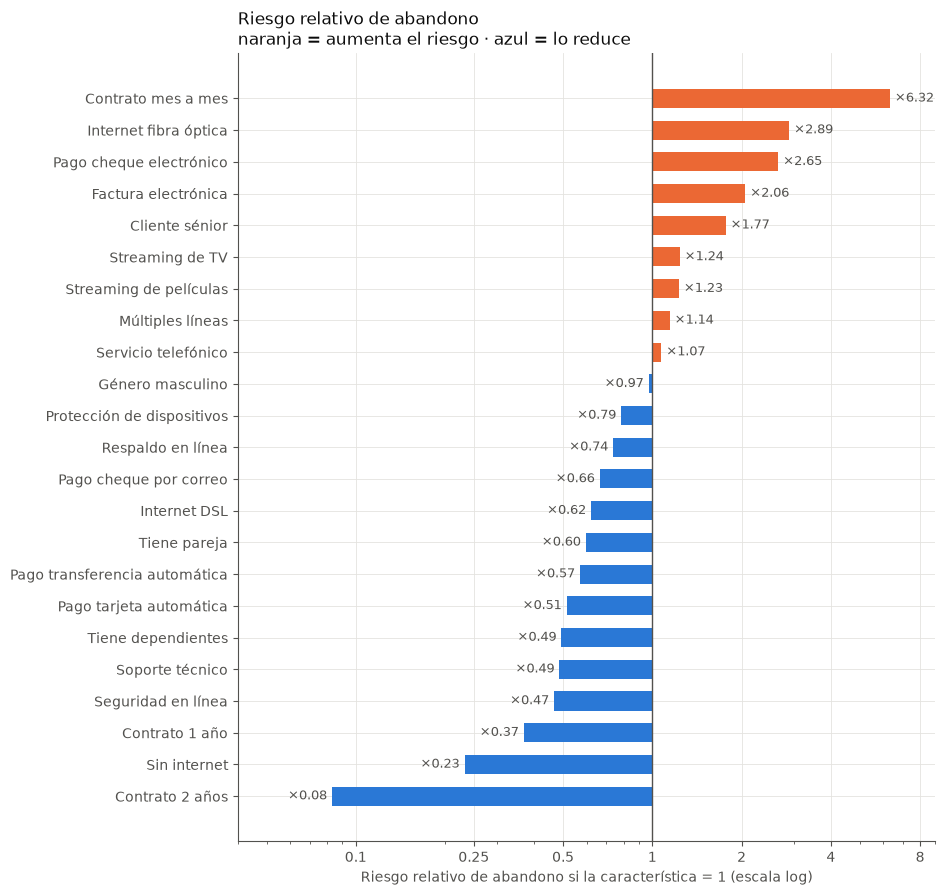

In [7]:
bb = b.sort_values("riesgo_relativo")
y = np.arange(len(bb))
fig, ax = plt.subplots(figsize=(9, 0.38 * len(bb) + 1.5))
ax.barh(y, bb["riesgo_relativo"] - 1, left=1, color=[CHURN if r > 1 else STAY for r in bb["riesgo_relativo"]], height=0.6)
ax.axvline(1, color=MUTED, lw=1)
for yi, r in zip(y, bb["riesgo_relativo"]):
    ax.text(r * 1.04 if r > 1 else r / 1.04, yi, f"×{r:.2f}", va="center", ha="left" if r > 1 else "right",
            color=MUTED, fontsize=9)
ax.set_yticks(y, bb["variable"].map(LABELS))
ax.set_xscale("log")
ax.set_xlim(0.04, 9)
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 8], ["0.1", "0.25", "0.5", "1", "2", "4", "8"])
ax.set_xlabel("Riesgo relativo de abandono si la característica = 1 (escala log)")
ax.set_title("Riesgo relativo de abandono\nnaranja = aumenta el riesgo · azul = lo reduce", loc="left")
style.save(fig, paths.figure("perfil", "perfil_riesgo_relativo.png"))

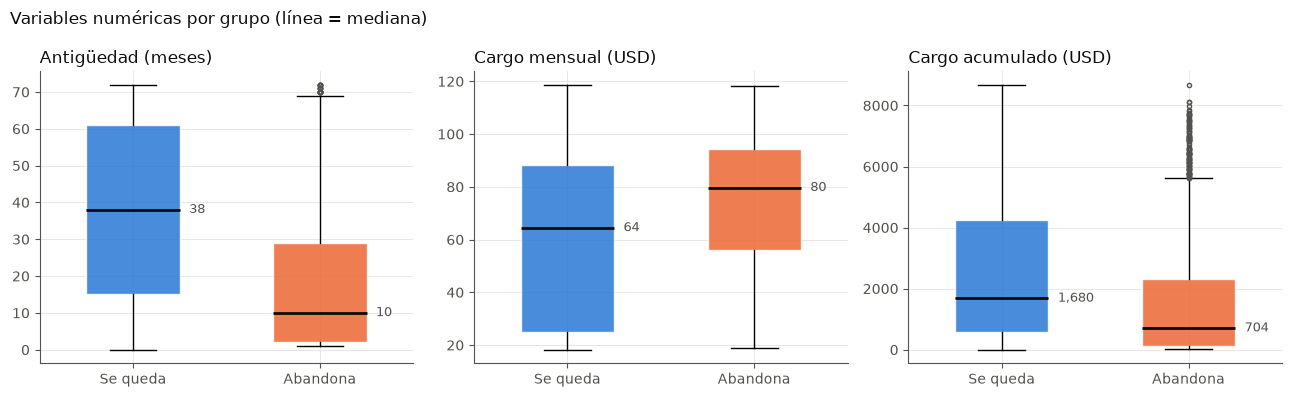

In [8]:
fig, axes = plt.subplots(1, len(NUMERIC), figsize=(13, 4))
for ax, c in zip(axes, NUMERIC):
    data = [df.loc[df.churn == k, c] for k in (0, 1)]
    bp = ax.boxplot(data, tick_labels=[GROUP[0], GROUP[1]], patch_artist=True, widths=0.5,
                    medianprops={"color": INK, "linewidth": 2}, flierprops={"markersize": 3, "markeredgecolor": MUTED})
    for patch, color in zip(bp["boxes"], (STAY, CHURN)):
        patch.set(facecolor=color, alpha=0.85, edgecolor="white")
    for i, d in enumerate(data, start=1):
        ax.text(i + 0.3, d.median(), f"{d.median():,.0f}", va="center", color=MUTED, fontsize=9)
    ax.set_title(LABELS[c], loc="left")
fig.suptitle("Variables numéricas por grupo (línea = mediana)", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("perfil", "perfil_numericas.png"))

## 4. Abandono según antigüedad
El abandono supera el 50 % en los primeros 6 meses y baja de 10 % después de 5 años.

tenure,0-5,6-11,12-17,18-23,24-29,30-35,36-41,42-47,48-53,54-59,60-65,66-72
% abandona,54.3,36.5,33.6,24.6,22.3,21.7,21.7,17.4,15.4,14.6,8.0,6.1


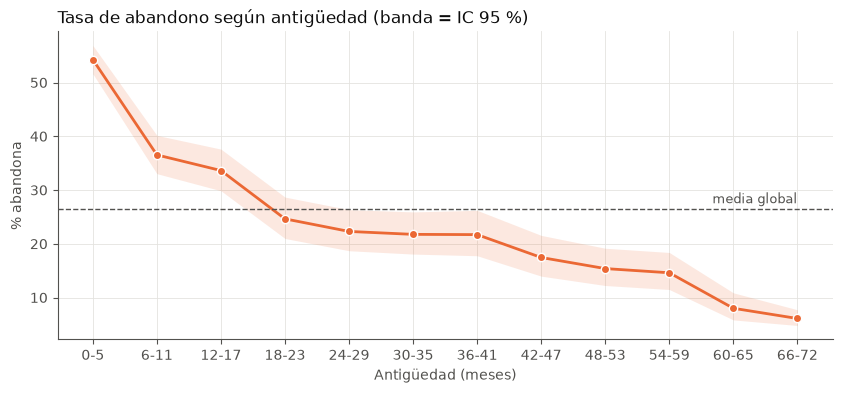

In [9]:
edges = [*range(-1, 66, 6), 72]  # último tramo 66-72 incluye tenure = 72
bins = pd.cut(df["tenure"], edges, labels=[f"{a + 1}-{b}" for a, b in zip(edges, edges[1:])])
assert bins.notna().all()
g = df.groupby(bins, observed=True)["churn"].agg(["sum", "count"])
ci_t = np.array([wilson(k, m) for k, m in zip(g["sum"], g["count"])]) * 100
rate = g["sum"] / g["count"] * 100
x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(x, ci_t[:, 0], ci_t[:, 1], color=CHURN, alpha=0.15, linewidth=0)
ax.plot(x, rate, color=CHURN, lw=2, marker="o", markersize=6, markeredgecolor="white")
ax.axhline(df.churn.mean() * 100, color=MUTED, ls="--", lw=1)
ax.text(len(g) - 1, df.churn.mean() * 100 + 1, "media global", ha="right", color=MUTED, fontsize=9)
ax.set_xticks(x, g.index)
ax.set_xlabel("Antigüedad (meses)")
ax.set_ylabel("% abandona")
ax.set_title("Tasa de abandono según antigüedad (banda = IC 95 %)", loc="left")
style.save(fig, paths.figure("perfil", "perfil_antiguedad.png"))
rate.round(1).to_frame("% abandona").T

## 5. ¿Se puede descartar el servicio telefónico? (paradoja de Simpson)
Por sí solo apenas se asocia con el abandono, pero los clientes sin teléfono son todos de DSL.
Dentro de DSL, quienes no tienen teléfono abandonan más: el efecto solo aparece al controlar
por tipo de internet, por eso la variable se conserva.

In [10]:
print("Clientes sin teléfono por tipo de internet:")
print(df.loc[df.phone_service == 0, ["internet_service_dsl", "internet_service_fiber_optic", "internet_service_no"]].sum().to_string())
dsl = df[df.internet_service_dsl == 1]
dsl.groupby("phone_service")["churn"].agg(clientes="count", pct_abandona=lambda s: s.mean() * 100).round(2)

Clientes sin teléfono por tipo de internet:
internet_service_dsl            682
internet_service_fiber_optic      0
internet_service_no               0


,clientes,pct_abandona
phone_service,,
0,682,24.93
1,1739,16.62


## 6. ¿El género aporta algo?
Tres pruebas antes de excluirlo del modelo:
1. Efecto global (chi-cuadrado).
2. Efecto oculto dentro de subgrupos (como el teléfono dentro de DSL), con corrección de Bonferroni.
3. Aporte predictivo: AUC con validación cruzada de un modelo con y sin género.

In [11]:
p = stats.chi2_contingency(pd.crosstab(df.gender_male, df.churn))[1]
print("1. Global: abandono mujeres {:.1%} vs hombres {:.1%}  p = {:.3f}".format(
    df.loc[df.gender_male == 0, "churn"].mean(), df.loc[df.gender_male == 1, "churn"].mean(), p))

strata = df.assign(
    tenure_tramo=pd.cut(df.tenure, [-1, 12, 24, 48, 72]).astype(str),
    cargo_tramo=pd.qcut(df.monthly_charges, 4).astype(str),
).drop(columns=["tenure", "monthly_charges", "total_charges", "gender_male", "churn"])
rows = []
for col in strata.columns:
    for val, idx in strata.groupby(col).groups.items():
        sub = df.loc[idx]
        if sub.gender_male.nunique() < 2 or len(sub) < 100:
            continue
        rows.append({
            "subgrupo": f"{col}={val}", "n": len(sub),
            "abandono_mujer": sub.loc[sub.gender_male == 0, "churn"].mean() * 100,
            "abandono_hombre": sub.loc[sub.gender_male == 1, "churn"].mean() * 100,
            "p": stats.chi2_contingency(pd.crosstab(sub.gender_male, sub.churn))[1],
        })
sub = pd.DataFrame(rows)
sub["dif_pp"] = sub.abandono_hombre - sub.abandono_mujer
sub["p_bonferroni"] = (sub.p * len(sub)).clip(upper=1)
print(f"2. Subgrupos evaluados: {len(sub)}. Significativos tras Bonferroni: {(sub.p_bonferroni < 0.05).sum()}")
sub.reindex(sub.dif_pp.abs().sort_values(ascending=False).index).head(8).round(3)

1. Global: abandono mujeres 26.9% vs hombres 26.2%  p = 0.487


2. Subgrupos evaluados: 52. Significativos tras Bonferroni: 0


,subgrupo,n,abandono_mujer,abandono_hombre,p,dif_pp,p_bonferroni
50,"cargo_tramo=(70.35, 89.85]",1757,39.665,35.267,0.064,-4.398,1.000
39,payment_method_credit_card_automatic=1,1522,17.420,13.117,0.024,-4.303,1.000
46,"tenure_tramo=(24, 48]",1594,22.236,18.504,0.074,-3.732,1.000
47,"tenure_tramo=(48, 72]",2239,7.791,11.150,0.008,3.359,0.437
44,"tenure_tramo=(-1, 12]",2186,48.985,45.917,0.163,-3.069,1.000
2,partner=0,3641,34.444,31.505,0.064,-2.940,1.000
11,online_security=1,2019,15.774,13.407,0.149,-2.367,1.000
8,multiple_lines=0,4072,26.124,23.961,0.120,-2.163,1.000


In [12]:
X, yy = df.drop(columns="churn"), df.churn
models = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
print("3. AUC (validación cruzada 5 folds × 3 repeticiones):")
for name, m in models.items():
    auc = {}
    for label, cols in (("con", X.columns), ("sin", X.columns.drop("gender_male"))):
        auc[label] = np.concatenate([
            cross_val_score(m, X[cols], yy, cv=StratifiedKFold(5, shuffle=True, random_state=s), scoring="roc_auc")
            for s in range(3)
        ])
    d = auc["con"] - auc["sin"]
    print(f"   {name:<20} con género {auc['con'].mean():.4f}  sin género {auc['sin'].mean():.4f}  "
          f"diferencia {d.mean():+.4f} ± {d.std():.4f}")

3. AUC (validación cruzada 5 folds × 3 repeticiones):


   Regresión logística  con género 0.8451  sin género 0.8452  diferencia -0.0001 ± 0.0003


   Gradient boosting    con género 0.8360  sin género 0.8356  diferencia +0.0004 ± 0.0022


**Conclusión:** el género no se asocia con el abandono ni globalmente ni dentro de ningún subgrupo,
y quitarlo no cambia el AUC. Se excluye de los modelos (`telco.data.EXCLUDE`).